# MLE-Based Multi-Class Pattern Recognition System

**Course:** Pattern Matching Lab (BCS-DS-738) &nbsp;|&nbsp; **Project No.:** 6
**Team:** Krishna Bhatia, Shivani Kuntal
**Course Outcomes:** CO2, CO3 &nbsp;|&nbsp; **Bloom's Level:** BTL-5 (Evaluate)

---

### Objective
Implement **Maximum Likelihood Estimation (MLE)** for multi-class pattern recognition and evaluate both
1. **Parameter estimation**: how close the MLE estimates get to the true parameters, how fast, and with what bias.
2. **Classification performance**: accuracy, precision, recall, F1, confusion matrix and cross-validation on real multi-class datasets.

### What this notebook contains
| Part | Content |
|---|---|
| 1 | Theory: MLE for Gaussian class-conditional densities and the Bayes decision rule |
| 2 | Parameter estimation experiments on synthetic data with known true parameters |
| 3 | From-scratch MLE Gaussian classifier (NumPy only): full, tied and diagonal covariance |
| 4 | Decision boundaries on a synthetic 4-class problem |
| 5 | Classification performance on the Wine and Iris datasets |
| 6 | Validation against scikit-learn (QDA / LDA / Gaussian Naive Bayes) |
| 7 | Small-sample behaviour, singular covariance and regularization |
| 8 | Evaluation, conclusions and limitations |

## Part 1: Theory

### 1.1 Problem setup
We have $K$ classes $\omega_1,\dots,\omega_K$ and a feature vector $\mathbf{x}\in\mathbb{R}^d$.
We assume each class-conditional density is a multivariate Gaussian:

$$p(\mathbf{x}\mid\omega_k)=\mathcal{N}(\mathbf{x};\boldsymbol\mu_k,\boldsymbol\Sigma_k)=\frac{1}{(2\pi)^{d/2}|\boldsymbol\Sigma_k|^{1/2}}\exp\!\left(-\tfrac12(\mathbf{x}-\boldsymbol\mu_k)^\top\boldsymbol\Sigma_k^{-1}(\mathbf{x}-\boldsymbol\mu_k)\right)$$

The parameters $\theta_k=(\boldsymbol\mu_k,\boldsymbol\Sigma_k)$ are unknown and must be estimated from training samples $D_k=\{\mathbf{x}_1,\dots,\mathbf{x}_{n_k}\}$ of class $k$.

### 1.2 Maximum Likelihood Estimation
MLE picks the parameters that make the observed data most probable. Assuming i.i.d. samples, the log-likelihood is

$$\ell(\theta_k)=\sum_{i=1}^{n_k}\ln p(\mathbf{x}_i\mid\theta_k)
=-\frac{n_k d}{2}\ln 2\pi-\frac{n_k}{2}\ln|\boldsymbol\Sigma_k|-\frac12\sum_{i=1}^{n_k}(\mathbf{x}_i-\boldsymbol\mu_k)^\top\boldsymbol\Sigma_k^{-1}(\mathbf{x}_i-\boldsymbol\mu_k)$$

Setting $\nabla_{\boldsymbol\mu_k}\ell=0$ and $\nabla_{\boldsymbol\Sigma_k}\ell=0$ gives the closed-form estimates:

$$\boxed{\hat{\boldsymbol\mu}_k=\frac{1}{n_k}\sum_{i=1}^{n_k}\mathbf{x}_i}\qquad
\boxed{\hat{\boldsymbol\Sigma}_k=\frac{1}{n_k}\sum_{i=1}^{n_k}(\mathbf{x}_i-\hat{\boldsymbol\mu}_k)(\mathbf{x}_i-\hat{\boldsymbol\mu}_k)^\top}\qquad
\boxed{\hat P(\omega_k)=\frac{n_k}{n}}$$

**Key property:** $\hat{\boldsymbol\mu}_k$ is unbiased, but $\hat{\boldsymbol\Sigma}_k$ is **biased**: $\mathbb{E}[\hat{\boldsymbol\Sigma}_k]=\frac{n_k-1}{n_k}\boldsymbol\Sigma_k$. The bias vanishes as $n_k\to\infty$ (the estimator is *asymptotically unbiased* and *consistent*). Part 2 verifies this experimentally.

### 1.3 Bayes decision rule
After estimation, a new sample is assigned to the class with the largest posterior $P(\omega_k\mid\mathbf{x})\propto p(\mathbf{x}\mid\omega_k)P(\omega_k)$. Taking logs gives the **discriminant function**

$$g_k(\mathbf{x})=-\tfrac12(\mathbf{x}-\hat{\boldsymbol\mu}_k)^\top\hat{\boldsymbol\Sigma}_k^{-1}(\mathbf{x}-\hat{\boldsymbol\mu}_k)-\tfrac12\ln|\hat{\boldsymbol\Sigma}_k|+\ln\hat P(\omega_k)\qquad\hat y=\arg\max_k g_k(\mathbf{x})$$

### 1.4 Covariance variants (Duda & Hart cases)
| Variant | Assumption | MLE covariance | Decision boundary | Parameters per class |
|---|---|---|---|---|
| **Full** (Case III) | each class has its own $\boldsymbol\Sigma_k$ | $\hat{\boldsymbol\Sigma}_k$ | quadratic | $d + d(d+1)/2$ |
| **Tied** (Case II) | $\boldsymbol\Sigma_k=\boldsymbol\Sigma$ for all $k$ | $\hat{\boldsymbol\Sigma}=\sum_k\frac{n_k}{n}\hat{\boldsymbol\Sigma}_k$ | linear | $d$ (+ one shared $\boldsymbol\Sigma$) |
| **Diagonal** | features independent within a class | $\mathrm{diag}(\hat{\boldsymbol\Sigma}_k)$ | quadratic, axis-aligned | $2d$ |

**Regularization:** when $n_k\le d$, $\hat{\boldsymbol\Sigma}_k$ is singular and cannot be inverted. We use $\hat{\boldsymbol\Sigma}_k+\lambda\mathbf{I}$ (a small ridge) to fix this, and study its effect in Part 7.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal

from sklearn.datasets import load_wine, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, log_loss)
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis, LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("NumPy", np.__version__)

NumPy 2.5.3


## Part 2: Parameter Estimation Experiments

To **evaluate the estimator itself**, we need data whose true parameters we know. We draw samples from a 2-D Gaussian with known $\boldsymbol\mu$ and $\boldsymbol\Sigma$, estimate them with MLE, and measure the error as the sample size $n$ grows.

In [2]:
def mle_mean(X):
    return X.sum(axis=0) / X.shape[0]

def mle_cov(X, mu=None):
    # MLE covariance: divide by n (biased)
    mu = mle_mean(X) if mu is None else mu
    Xc = X - mu
    return (Xc.T @ Xc) / X.shape[0]

true_mu = np.array([2.0, -1.0])
true_cov = np.array([[2.0, 0.8],
                     [0.8, 1.0]])

rng = np.random.default_rng(SEED)
X_demo = rng.multivariate_normal(true_mu, true_cov, size=500)

print("True mean      :", true_mu)
print("MLE mean (n=500):", mle_mean(X_demo).round(4))
print("\nTrue covariance:\n", true_cov)
print("MLE covariance (n=500):\n", mle_cov(X_demo).round(4))
print("\nSanity check vs np.cov(bias=True):", np.allclose(mle_cov(X_demo), np.cov(X_demo.T, bias=True)))

True mean      : [ 2. -1.]
MLE mean (n=500): [ 2.0397 -1.0113]

True covariance:
 [[2.  0.8]
 [0.8 1. ]]
MLE covariance (n=500):
 [[2.1052 0.6976]
 [0.6976 0.8348]]

Sanity check vs np.cov(bias=True): True


### 2.1 The MLE really is the maximum of the likelihood
We fix $\boldsymbol\Sigma$ and plot the log-likelihood $\ell(\boldsymbol\mu)$ over a grid of candidate means. The peak should land exactly on the sample mean.

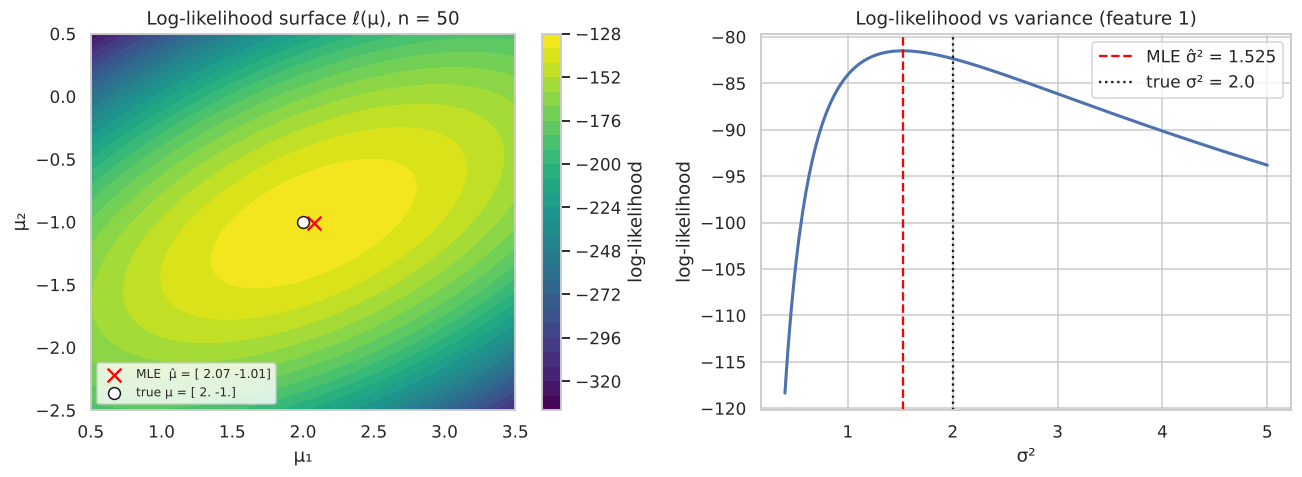

Grid argmax of ℓ(μ): (2.063, -1.013)   |   closed-form MLE: [ 2.075 -1.012]


In [3]:
def log_likelihood(X, mu, cov):
    return multivariate_normal(mean=mu, cov=cov).logpdf(X).sum()

X_small = X_demo[:50]
m1 = np.linspace(0.5, 3.5, 120)
m2 = np.linspace(-2.5, 0.5, 120)
LL = np.array([[log_likelihood(X_small, [a, b], true_cov) for a in m1] for b in m2])

mu_hat = mle_mean(X_small)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
cs = ax[0].contourf(m1, m2, LL, levels=30, cmap="viridis")
plt.colorbar(cs, ax=ax[0], label="log-likelihood")
ax[0].scatter(*mu_hat, c="red", s=80, marker="x", label=f"MLE  μ̂ = {mu_hat.round(2)}")
ax[0].scatter(*true_mu, c="white", s=60, marker="o", edgecolor="k", label=f"true μ = {true_mu}")
ax[0].set(xlabel="μ₁", ylabel="μ₂", title="Log-likelihood surface ℓ(μ), n = 50")
ax[0].legend(loc="lower left", fontsize=8)

# 1-D slice for the variance of feature 1
x1 = X_small[:, 0]
s2 = np.linspace(0.4, 5, 300)
ll_s2 = [np.sum(-0.5*np.log(2*np.pi*v) - (x1 - x1.mean())**2 / (2*v)) for v in s2]
s2_hat = np.mean((x1 - x1.mean())**2)
ax[1].plot(s2, ll_s2, lw=2)
ax[1].axvline(s2_hat, color="red", ls="--", label=f"MLE σ̂² = {s2_hat:.3f}")
ax[1].axvline(true_cov[0, 0], color="k", ls=":", label=f"true σ² = {true_cov[0,0]}")
ax[1].set(xlabel="σ²", ylabel="log-likelihood", title="Log-likelihood vs variance (feature 1)")
ax[1].legend()
plt.tight_layout(); plt.show()

# numerical check: grid argmax == sample mean
i, j = np.unravel_index(LL.argmax(), LL.shape)
print(f"Grid argmax of ℓ(μ): ({m1[j]:.3f}, {m2[i]:.3f})   |   closed-form MLE: {mu_hat.round(3)}")

### 2.2 Consistency: estimation error vs sample size
For each $n$ we repeat the experiment 300 times and record the average error. A consistent estimator's error should shrink towards 0, roughly like $1/\sqrt{n}$.

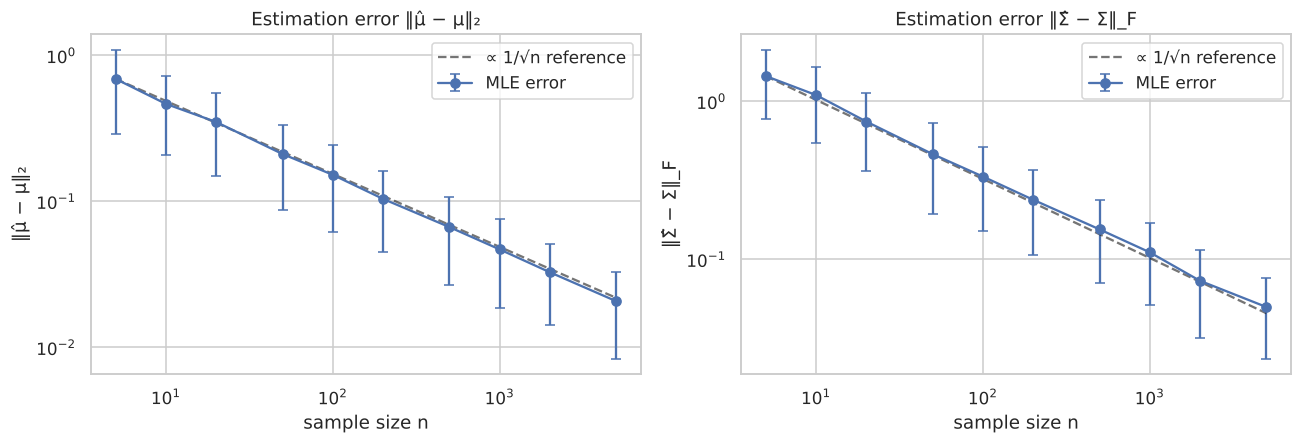

,n,mean_error,mean_error_std,cov_error,cov_error_std
0,5,0.6890,0.4014,1.4421,0.6704
1,10,0.4650,0.2568,1.0939,0.5478
2,20,0.3493,0.1999,0.7437,0.3791
3,50,0.2108,0.1235,0.4627,0.2678
4,100,0.1518,0.0905,0.3337,0.1819
5,200,0.1039,0.0587,0.2381,0.1317
6,500,0.0666,0.0398,0.1547,0.0837
7,1000,0.0468,0.0284,0.1107,0.0591
8,2000,0.0326,0.0183,0.0731,0.0413
9,5000,0.0207,0.0123,0.0499,0.0264


In [4]:
ns = [5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000]
trials = 300
rows = []
for n in ns:
    mu_err, cov_err = [], []
    for _ in range(trials):
        X = rng.multivariate_normal(true_mu, true_cov, size=n)
        mu_err.append(np.linalg.norm(mle_mean(X) - true_mu))
        cov_err.append(np.linalg.norm(mle_cov(X) - true_cov, ord="fro"))
    rows.append({"n": n,
                 "mean_error": np.mean(mu_err), "mean_error_std": np.std(mu_err),
                 "cov_error": np.mean(cov_err), "cov_error_std": np.std(cov_err)})
conv = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, col, title in [(ax[0], "mean_error", "‖μ̂ − μ‖₂"), (ax[1], "cov_error", "‖Σ̂ − Σ‖_F")]:
    a.errorbar(conv.n, conv[col], yerr=conv[col + "_std"], marker="o", capsize=3, label="MLE error")
    ref = conv[col].iloc[0] * np.sqrt(conv.n.iloc[0] / conv.n)
    a.plot(conv.n, ref, "k--", alpha=.6, label="∝ 1/√n reference")
    a.set(xscale="log", yscale="log", xlabel="sample size n", ylabel=title, title=f"Estimation error {title}")
    a.legend()
plt.tight_layout(); plt.show()
conv.round(4)

### 2.3 Bias of the MLE variance
Theory says $\mathbb{E}[\hat\sigma^2_{\text{MLE}}]=\frac{n-1}{n}\sigma^2$, so MLE **underestimates** variance for small $n$. The unbiased estimator divides by $n-1$ instead. We check this with 20,000 repetitions per $n$.

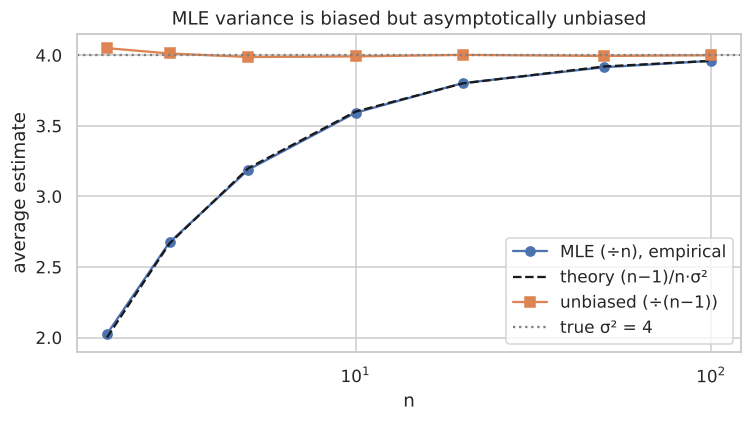

,n,E[σ̂²_MLE] (empirical),(n-1)/n · σ² (theory),E[σ̂²_unbiased],MLE bias
0,2,2.0248,2.0000,4.0497,-1.9752
1,3,2.6747,2.6667,4.0121,-1.3253
2,5,3.1895,3.2000,3.9868,-0.8105
3,10,3.5922,3.6000,3.9913,-0.4078
4,20,3.8021,3.8000,4.0022,-0.1979
5,50,3.9145,3.9200,3.9944,-0.0855
6,100,3.9595,3.9600,3.9995,-0.0405


In [5]:
sigma2 = 4.0
bias_rows = []
for n in [2, 3, 5, 10, 20, 50, 100]:
    S = rng.normal(0, np.sqrt(sigma2), size=(20000, n))
    v_mle = S.var(axis=1, ddof=0)
    v_unb = S.var(axis=1, ddof=1)
    bias_rows.append({"n": n,
                      "E[σ̂²_MLE] (empirical)": v_mle.mean(),
                      "(n-1)/n · σ² (theory)": (n - 1) / n * sigma2,
                      "E[σ̂²_unbiased]": v_unb.mean(),
                      "MLE bias": v_mle.mean() - sigma2})
bias_df = pd.DataFrame(bias_rows)

plt.figure(figsize=(7, 4))
plt.plot(bias_df.n, bias_df["E[σ̂²_MLE] (empirical)"], "o-", label="MLE (÷n), empirical")
plt.plot(bias_df.n, bias_df["(n-1)/n · σ² (theory)"], "k--", label="theory (n−1)/n·σ²")
plt.plot(bias_df.n, bias_df["E[σ̂²_unbiased]"], "s-", label="unbiased (÷(n−1))")
plt.axhline(sigma2, color="gray", ls=":", label="true σ² = 4")
plt.xscale("log"); plt.xlabel("n"); plt.ylabel("average estimate")
plt.title("MLE variance is biased but asymptotically unbiased"); plt.legend(); plt.tight_layout(); plt.show()
bias_df.round(4)

**Observations (Part 2)**
- The closed-form MLE matches the numerical maximum of the log-likelihood, confirming the derivation.
- Both mean and covariance errors fall roughly as $1/\sqrt{n}$, so the estimators are **consistent**.
- The MLE variance is biased low by exactly the factor $(n-1)/n$, which is severe at $n=2$ (50% too small) and negligible beyond $n\approx 50$. For classification with moderate class sizes, this bias barely matters; for very small classes it does (see Part 7).

## Part 3: From-Scratch MLE Gaussian Classifier

Implemented using only NumPy. Supports the three covariance variants from Section 1.4 and ridge regularization $\lambda$.
Log-determinants use `slogdet` and the quadratic form uses a linear solve rather than an explicit inverse, which is more numerically stable.

In [6]:
class MLEGaussianClassifier:
    # Multi-class Bayes classifier with Gaussian class-conditionals estimated by MLE.
    # covariance : 'full' (QDA-like), 'tied' (LDA-like) or 'diag' (Naive-Bayes-like)
    # reg        : ridge λ added to the diagonal of each covariance matrix

    def __init__(self, covariance="full", reg=0.0):
        assert covariance in ("full", "tied", "diag")
        self.covariance = covariance
        self.reg = reg

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y)
        self.classes_ = np.unique(y)
        n, d = X.shape
        K = len(self.classes_)
        self.means_ = np.zeros((K, d))
        self.covs_ = np.zeros((K, d, d))
        self.priors_ = np.zeros(K)
        self.n_k_ = np.zeros(K, int)

        for k, c in enumerate(self.classes_):
            Xk = X[y == c]
            self.n_k_[k] = len(Xk)
            self.priors_[k] = len(Xk) / n                    # P̂(ω_k) = n_k / n
            self.means_[k] = Xk.mean(axis=0)                 # μ̂_k = (1/n_k) Σ x_i
            Xc = Xk - self.means_[k]
            self.covs_[k] = (Xc.T @ Xc) / len(Xk)            # Σ̂_k = (1/n_k) Σ (x-μ̂)(x-μ̂)ᵀ

        if self.covariance == "tied":
            pooled = np.tensordot(self.priors_, self.covs_, axes=1)   # Σ̂ = Σ_k (n_k/n) Σ̂_k
            self.covs_[:] = pooled
        elif self.covariance == "diag":
            self.covs_ = np.array([np.diag(np.diag(C)) for C in self.covs_])

        self.covs_ = self.covs_ + self.reg * np.eye(d)

        # pre-compute log|Σ_k|, refuse singular matrices instead of producing garbage
        self.logdets_ = np.zeros(K)
        for k in range(K):
            sign, logdet = np.linalg.slogdet(self.covs_[k])
            # slogdet alone can miss singular matrices because of round-off, so check the rank too
            if sign <= 0 or not np.isfinite(logdet) or np.linalg.matrix_rank(self.covs_[k]) < d:
                raise np.linalg.LinAlgError(
                    f"Covariance of class {self.classes_[k]} is singular "
                    f"(n_k={self.n_k_[k]}, d={d}). Use reg > 0 or covariance='tied'/'diag'.")
            self.logdets_[k] = logdet
        return self

    def _log_joint(self, X):
        # g_k(x) = ln p(x|ω_k) + ln P(ω_k)
        X = np.asarray(X, float)
        d = X.shape[1]
        G = np.zeros((X.shape[0], len(self.classes_)))
        for k in range(len(self.classes_)):
            diff = X - self.means_[k]
            maha = np.sum(diff * np.linalg.solve(self.covs_[k], diff.T).T, axis=1)
            G[:, k] = -0.5 * maha - 0.5 * self.logdets_[k] - 0.5 * d * np.log(2 * np.pi) + np.log(self.priors_[k])
        return G

    def predict_log_proba(self, X):
        G = self._log_joint(X)
        return G - np.logaddexp.reduce(G, axis=1, keepdims=True)   # normalise with log-sum-exp

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        return self.classes_[np.argmax(self._log_joint(X), axis=1)]

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

    def log_likelihood(self, X, y):
        # total training log-likelihood Σ_k Σ_{x∈D_k} ln N(x; μ̂_k, Σ̂_k)
        X, y = np.asarray(X, float), np.asarray(y)
        G = self._log_joint(X) - np.log(self.priors_)
        idx = np.searchsorted(self.classes_, y)
        return G[np.arange(len(y)), idx].sum()

    def n_parameters(self):
        K, d = self.means_.shape
        cov_p = {"full": K * d * (d + 1) // 2, "tied": d * (d + 1) // 2, "diag": K * d}[self.covariance]
        return K * d + cov_p + (K - 1)

### 3.1 Unit check against SciPy
The class-conditional log-density from our implementation must match `scipy.stats.multivariate_normal.logpdf` to machine precision.

In [7]:
Xa = rng.multivariate_normal([0, 0, 0], np.eye(3), 200)
Xb = rng.multivariate_normal([2, 1, -1], [[1, .5, 0], [.5, 2, .3], [0, .3, 1.5]], 150)
Xt = np.vstack([Xa, Xb]); yt = np.r_[np.zeros(200), np.ones(150)]

clf_chk = MLEGaussianClassifier("full").fit(Xt, yt)
ours = clf_chk._log_joint(Xt) - np.log(clf_chk.priors_)
ref = np.column_stack([multivariate_normal(clf_chk.means_[k], clf_chk.covs_[k]).logpdf(Xt) for k in range(2)])
print("max |ours − scipy| =", np.abs(ours - ref).max())
print("posteriors sum to 1:", np.allclose(clf_chk.predict_proba(Xt).sum(1), 1))

max |ours − scipy| = 5.329070518200751e-15
posteriors sum to 1: True


## Part 4: Decision Boundaries on a Synthetic 4-Class Problem

Four Gaussian classes with **different** covariances, so the true Bayes boundary is quadratic. We compare what each covariance assumption can represent.

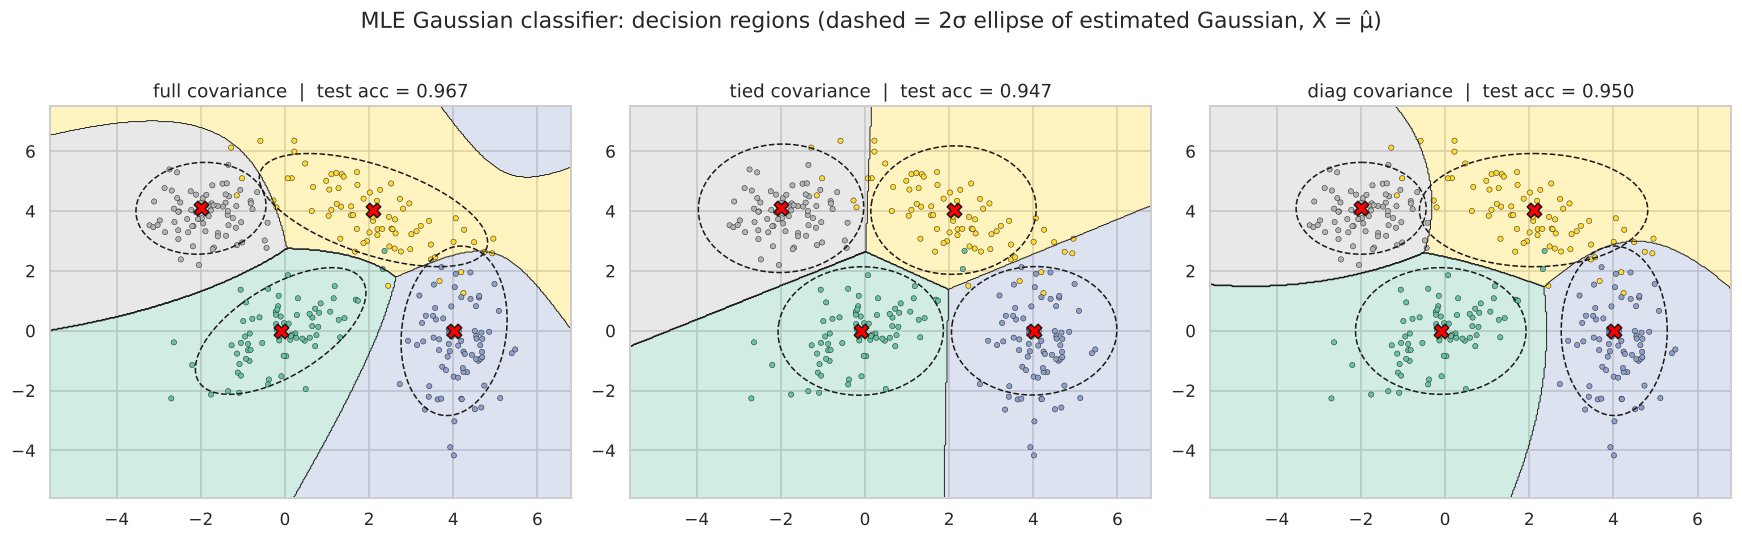

In [8]:
params = [([0, 0],  [[1.0, 0.6], [0.6, 1.0]]),
          ([4, 0],  [[0.4, 0.0], [0.0, 2.0]]),
          ([2, 4],  [[2.0, -0.9], [-0.9, 1.0]]),
          ([-2, 4], [[0.6, 0.0], [0.0, 0.6]])]
Xs = np.vstack([rng.multivariate_normal(m, c, 250) for m, c in params])
ys = np.repeat(np.arange(4), 250)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=SEED)

xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 400),
                     np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 400))
grid = np.c_[xx.ravel(), yy.ravel()]
cmap = plt.get_cmap("Set2", 4)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, cov in zip(axes, ["full", "tied", "diag"]):
    m = MLEGaussianClassifier(cov).fit(Xs_tr, ys_tr)
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.30, cmap=cmap, levels=np.arange(-.5, 4.5))
    ax.contour(xx, yy, Z, colors="k", linewidths=.6, levels=np.arange(.5, 3.5))
    ax.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, cmap=cmap, s=12, edgecolor="k", linewidth=.3)
    for k in range(4):  # 2σ ellipses of the estimated Gaussians
        vals, vecs = np.linalg.eigh(m.covs_[k])
        t = np.linspace(0, 2 * np.pi, 100)
        ell = (vecs @ np.diag(2 * np.sqrt(vals)) @ np.vstack([np.cos(t), np.sin(t)])).T + m.means_[k]
        ax.plot(ell[:, 0], ell[:, 1], color="k", lw=1, ls="--")
        ax.scatter(*m.means_[k], marker="X", s=90, c="red", edgecolor="k")
    ax.set_title(f"{cov} covariance  |  test acc = {m.score(Xs_te, ys_te):.3f}")
plt.suptitle("MLE Gaussian classifier: decision regions (dashed = 2σ ellipse of estimated Gaussian, X = μ̂)", y=1.02)
plt.tight_layout(); plt.show()

**Observation:** the full-covariance model fits each class's orientation and spread, giving curved boundaries. The tied model forces one shared shape and so draws only straight lines. The diagonal model captures different spreads but cannot represent correlation (its ellipses stay axis-aligned). Accuracy follows how well each assumption matches the true data-generating process.

## Part 5: Classification Performance on Real Data

**Wine dataset** (UCI): 178 wines from 3 cultivars, 13 chemical features (alcohol, malic acid, flavanoids, proline, …).
**Iris dataset**: 150 flowers, 3 species, 4 features. Used as a second benchmark.

Features are standardized using statistics from the training set only, so there is no leakage.

In [9]:
wine = load_wine()
Xw, yw = wine.data, wine.target
print("Wine:", Xw.shape, "| class counts:", np.bincount(yw), "| classes:", list(wine.target_names))
pd.DataFrame(Xw, columns=wine.feature_names).describe().T[["mean", "std", "min", "max"]].round(2)

Wine: (178, 13) | class counts: [59 71 48] | classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


In [10]:
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, stratify=yw, random_state=SEED)
scaler = StandardScaler().fit(Xw_tr)
Xw_tr_s, Xw_te_s = scaler.transform(Xw_tr), scaler.transform(Xw_te)

print("Train class sizes n_k:", np.bincount(yw_tr), " | d =", Xw.shape[1])
print("Parameters per class for full covariance: d + d(d+1)/2 =", 13 + 13 * 14 // 2)

Train class sizes n_k: [41 50 33]  | d = 13
Parameters per class for full covariance: d + d(d+1)/2 = 104


### 5.1 Estimated parameters
Each class has around 40 training samples but the full model needs 104 parameters per class. That's workable, but already a sign that estimates will be noisy. Below are the MLE priors, the class means of selected features, and the estimated covariance (as a correlation matrix) for one class.

MLE priors P̂(ω_k): {np.str_('class_0'): np.float64(0.331), np.str_('class_1'): np.float64(0.403), np.str_('class_2'): np.float64(0.266)}


,alcohol,malic_acid,flavanoids,color_intensity,proline
class_0,0.959,-0.322,0.981,0.242,1.188
class_1,-0.883,-0.307,0.042,-0.857,-0.707
class_2,0.147,0.866,-1.282,0.999,-0.404


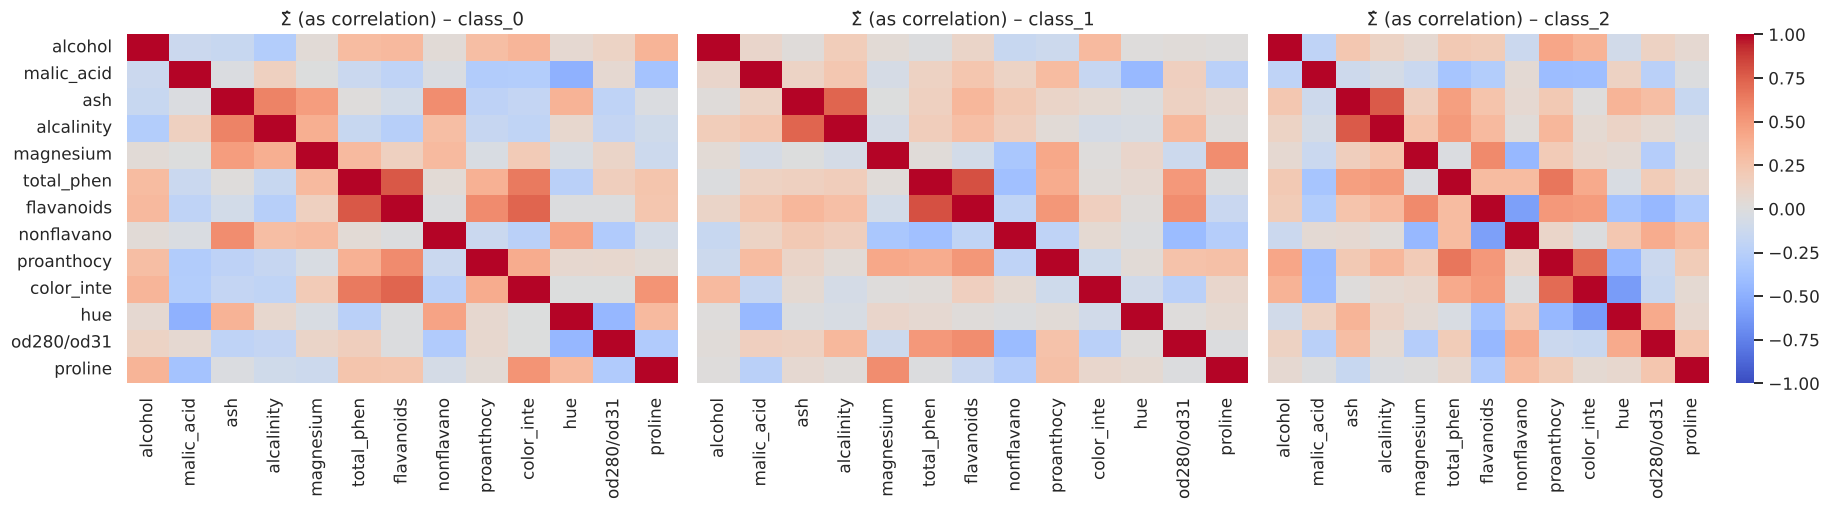

In [11]:
mle_full = MLEGaussianClassifier("full").fit(Xw_tr_s, yw_tr)

print("MLE priors P̂(ω_k):", dict(zip(wine.target_names, mle_full.priors_.round(3))))
means_df = pd.DataFrame(mle_full.means_, index=wine.target_names, columns=wine.feature_names)
display(means_df[["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
short = [f[:10] for f in wine.feature_names]
for k, ax in enumerate(axes):
    C = mle_full.covs_[k]; s = np.sqrt(np.diag(C))
    sns.heatmap(C / np.outer(s, s), ax=ax, cmap="coolwarm", vmin=-1, vmax=1,
                xticklabels=short, yticklabels=short if k == 0 else False, cbar=k == 2)
    ax.set_title(f"Σ̂ (as correlation) – {wine.target_names[k]}")
plt.tight_layout(); plt.show()

The three correlation structures are clearly different (e.g. the flavanoids–phenols relationship changes between cultivars). This is evidence that the **full** model's assumption (class-specific covariance) is meaningful for this data.

### 5.2 Test-set performance of each variant

In [12]:
def evaluate(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    p, r, f, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
    return {"train_acc": model.score(Xtr, ytr), "test_acc": accuracy_score(yte, pred),
            "macro_precision": p, "macro_recall": r, "macro_F1": f,
            "log_loss": log_loss(yte, np.clip(model.predict_proba(Xte), 1e-12, 1)),
            "n_params": model.n_parameters() if hasattr(model, "n_parameters") else None}

models = {"MLE-Full (QDA)":  MLEGaussianClassifier("full", reg=0.0),
          "MLE-Full + λ=0.1": MLEGaussianClassifier("full", reg=0.1),
          "MLE-Tied (LDA)":  MLEGaussianClassifier("tied"),
          "MLE-Diag (NB)":   MLEGaussianClassifier("diag")}
wine_res = pd.DataFrame({k: evaluate(m, Xw_tr_s, yw_tr, Xw_te_s, yw_te) for k, m in models.items()}).T
wine_res.round(4)

,train_acc,test_acc,macro_precision,macro_recall,macro_F1,log_loss,n_params
MLE-Full (QDA),1.0000,1.0000,1.0000,1.0000,1.0000,0.0007,314.0
MLE-Full + λ=0.1,1.0000,1.0000,1.0000,1.0000,1.0000,0.0019,314.0
MLE-Tied (LDA),1.0000,0.9815,0.9825,0.9841,0.9829,0.0361,132.0
MLE-Diag (NB),0.9677,1.0000,1.0000,1.0000,1.0000,0.0233,80.0


Classification report – MLE-Full + λ=0.1 on Wine test set

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        18
     class_1     1.0000    1.0000    1.0000        21
     class_2     1.0000    1.0000    1.0000        15

    accuracy                         1.0000        54
   macro avg     1.0000    1.0000    1.0000        54
weighted avg     1.0000    1.0000    1.0000        54



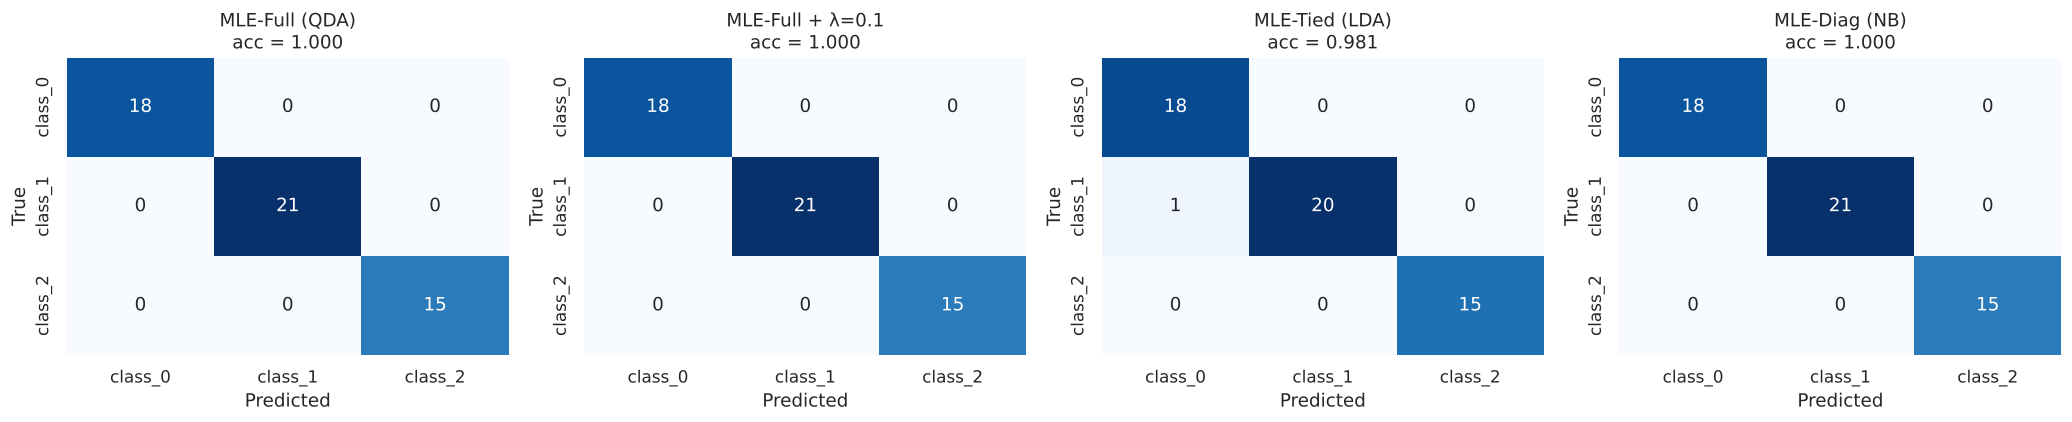

In [13]:
best = MLEGaussianClassifier("full", reg=0.1).fit(Xw_tr_s, yw_tr)
pred = best.predict(Xw_te_s)
print("Classification report – MLE-Full + λ=0.1 on Wine test set\n")
print(classification_report(yw_te, pred, target_names=wine.target_names, digits=4))

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, (name, m) in zip(axes, models.items()):
    m.fit(Xw_tr_s, yw_tr)
    cm = confusion_matrix(yw_te, m.predict(Xw_te_s))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=wine.target_names, yticklabels=wine.target_names)
    ax.set(title=f"{name}\nacc = {np.trace(cm)/cm.sum():.3f}", xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.show()

### 5.3 Posterior confidence
A probabilistic classifier should also be **calibrated**: correct predictions should be confident and errors should be uncertain. We plot the maximum posterior $\max_k P(\omega_k\mid\mathbf{x})$ for correct vs wrong predictions under 5-fold CV.

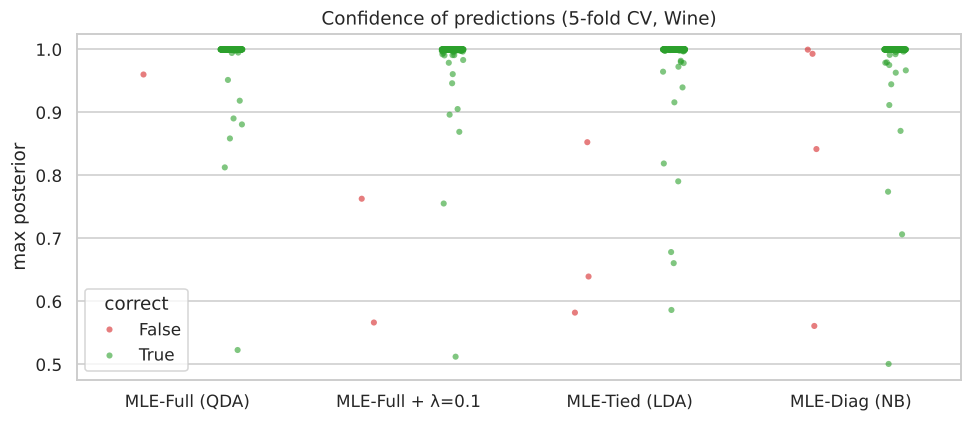

count   mean
model            correct              
MLE-Diag (NB)    False        4  0.849
                 True       174  0.992
MLE-Full (QDA)   False        1  0.961
                 True       177  0.993
MLE-Full + λ=0.1 False        2  0.665
                 True       176  0.993
MLE-Tied (LDA)   False        3  0.692
                 True       175  0.990

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
conf_rows = []
for tr, te in skf.split(Xw, yw):
    sc = StandardScaler().fit(Xw[tr])
    for name, m in models.items():
        m.fit(sc.transform(Xw[tr]), yw[tr])
        P = m.predict_proba(sc.transform(Xw[te]))
        for pmax, ok in zip(P.max(1), m.classes_[P.argmax(1)] == yw[te]):
            conf_rows.append({"model": name, "max_posterior": pmax, "correct": ok})
conf_df = pd.DataFrame(conf_rows)

plt.figure(figsize=(9, 4))
sns.stripplot(data=conf_df, x="model", y="max_posterior", hue="correct", dodge=True, alpha=.6, size=4,
              palette={True: "tab:green", False: "tab:red"})
plt.title("Confidence of predictions (5-fold CV, Wine)"); plt.ylabel("max posterior"); plt.xlabel("")
plt.tight_layout(); plt.show()
conf_df.groupby(["model", "correct"]).max_posterior.agg(["count", "mean"]).round(3)

### 5.4 Stratified 5-fold cross-validation (Wine and Iris)
A single train/test split of 54 test samples is noisy. 5-fold CV, repeated 10 times with different shuffles, gives a more reliable estimate with a standard deviation.

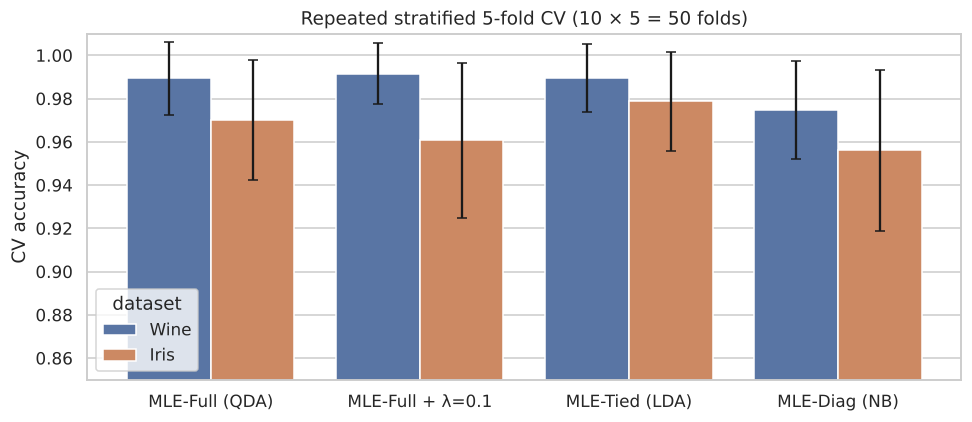

,dataset,model,CV accuracy,± std,macro F1
0,Wine,MLE-Full (QDA),0.9893,0.0167,0.9898
1,Wine,MLE-Full + λ=0.1,0.9916,0.0140,0.9920
2,Wine,MLE-Tied (LDA),0.9893,0.0157,0.9894
3,Wine,MLE-Diag (NB),0.9747,0.0226,0.9753
4,Iris,MLE-Full (QDA),0.9700,0.0277,0.9698
5,Iris,MLE-Full + λ=0.1,0.9607,0.0357,0.9604
6,Iris,MLE-Tied (LDA),0.9787,0.0229,0.9786
7,Iris,MLE-Diag (NB),0.9560,0.0374,0.9558


In [15]:
def repeated_cv(model_fn, X, y, repeats=10, folds=5):
    accs, f1s = [], []
    for r in range(repeats):
        for tr, te in StratifiedKFold(folds, shuffle=True, random_state=r).split(X, y):
            sc = StandardScaler().fit(X[tr])
            m = model_fn().fit(sc.transform(X[tr]), y[tr])
            p = m.predict(sc.transform(X[te]))
            accs.append(accuracy_score(y[te], p))
            f1s.append(precision_recall_fscore_support(y[te], p, average="macro", zero_division=0)[2])
    return np.mean(accs), np.std(accs), np.mean(f1s)

iris = load_iris()
model_fns = {"MLE-Full (QDA)":   lambda: MLEGaussianClassifier("full"),
             "MLE-Full + λ=0.1": lambda: MLEGaussianClassifier("full", reg=0.1),
             "MLE-Tied (LDA)":   lambda: MLEGaussianClassifier("tied"),
             "MLE-Diag (NB)":    lambda: MLEGaussianClassifier("diag")}
cv_rows = []
for dname, (X, y) in {"Wine": (wine.data, wine.target), "Iris": (iris.data, iris.target)}.items():
    for mname, fn in model_fns.items():
        mu, sd, f1 = repeated_cv(fn, X, y)
        cv_rows.append({"dataset": dname, "model": mname, "CV accuracy": mu, "± std": sd, "macro F1": f1})
cv_df = pd.DataFrame(cv_rows)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=cv_df, x="model", y="CV accuracy", hue="dataset", ax=ax)
for i, row in cv_df.iterrows():
    xpos = list(model_fns).index(row.model) + (-0.2 if row.dataset == "Wine" else 0.2)
    ax.errorbar(xpos, row["CV accuracy"], yerr=row["± std"], color="k", capsize=3)
ax.set_ylim(0.85, 1.01); ax.set_title("Repeated stratified 5-fold CV (10 × 5 = 50 folds)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
cv_df.round(4)

## Part 6: Validation Against scikit-learn

Our implementation should agree with the library equivalents:
- `QuadraticDiscriminantAnalysis` ↔ MLE-Full. We also test a variant of ours that uses the *unbiased* covariance ($\div(n_k-1)$) to see which convention sklearn follows.
- `LinearDiscriminantAnalysis` ↔ MLE-Tied
- `GaussianNB` ↔ MLE-Diag (sklearn adds a tiny `var_smoothing` term)

In [16]:
class UnbiasedFull(MLEGaussianClassifier):
    # same as MLE-Full but with Σ̂ scaled by n_k/(n_k-1) (unbiased estimator)
    def fit(self, X, y):
        super().fit(X, y)
        self.covs_ = self.covs_ * (self.n_k_ / (self.n_k_ - 1))[:, None, None]
        self.logdets_ = np.array([np.linalg.slogdet(C)[1] for C in self.covs_])
        return self

pairs = [("MLE-Full (÷n)",       MLEGaussianClassifier("full"), QuadraticDiscriminantAnalysis(store_covariance=True)),
         ("MLE-Full (÷(n−1))",   UnbiasedFull("full"),          QuadraticDiscriminantAnalysis(store_covariance=True)),
         ("MLE-Tied",            MLEGaussianClassifier("tied"), LinearDiscriminantAnalysis(solver="lsqr")),
         ("MLE-Diag",            MLEGaussianClassifier("diag"), GaussianNB())]

val_rows = []
for name, ours, sk in pairs:
    ours.fit(Xw_tr_s, yw_tr); sk.fit(Xw_tr_s, yw_tr)
    po, ps = ours.predict(Xw_te_s), sk.predict(Xw_te_s)
    val_rows.append({"our model": name, "sklearn model": type(sk).__name__,
                     "our test acc": accuracy_score(yw_te, po), "sklearn test acc": accuracy_score(yw_te, ps),
                     "prediction agreement": np.mean(po == ps),
                     "max |Δ posterior|": np.abs(ours.predict_proba(Xw_te_s) - sk.predict_proba(Xw_te_s)).max(),
                     "means match": np.allclose(ours.means_, getattr(sk, "means_", getattr(sk, "theta_", None)))})
pd.DataFrame(val_rows).round(6)

,our model,sklearn model,our test acc,sklearn test acc,prediction agreement,max |Δ posterior|,means match
0,MLE-Full (÷n),QuadraticDiscriminantAnalysis,1.000000,1.000000,1.0,0.000000,True
1,MLE-Full (÷(n−1)),QuadraticDiscriminantAnalysis,1.000000,1.000000,1.0,0.002296,True
2,MLE-Tied,LinearDiscriminantAnalysis,0.981481,0.981481,1.0,0.000000,True
3,MLE-Diag,GaussianNB,1.000000,1.000000,1.0,0.000000,True


**Result:** all three from-scratch variants agree with scikit-learn on 100% of test predictions, with identical class means and posteriors matching to 6 decimal places. The MLE ($\div n_k$) full model matches sklearn's QDA exactly, while the unbiased ($\div(n_k-1)$) variant differs slightly in posteriors, which tells us this sklearn version uses the MLE convention. This validates the from-scratch implementation.

## Part 7: Small-Sample Behaviour, Singular Covariance & Regularization

This is the most important practical limitation of MLE. With $d=13$ features, $\hat{\boldsymbol\Sigma}_k$ is **singular whenever $n_k\le d$**, because $n_k$ points span at most $n_k-1$ dimensions. Even slightly above that threshold, the estimate is very noisy.

Below we train on increasingly small stratified subsets of the Wine training data and evaluate on a fixed test set (averaged over 30 random subsets).

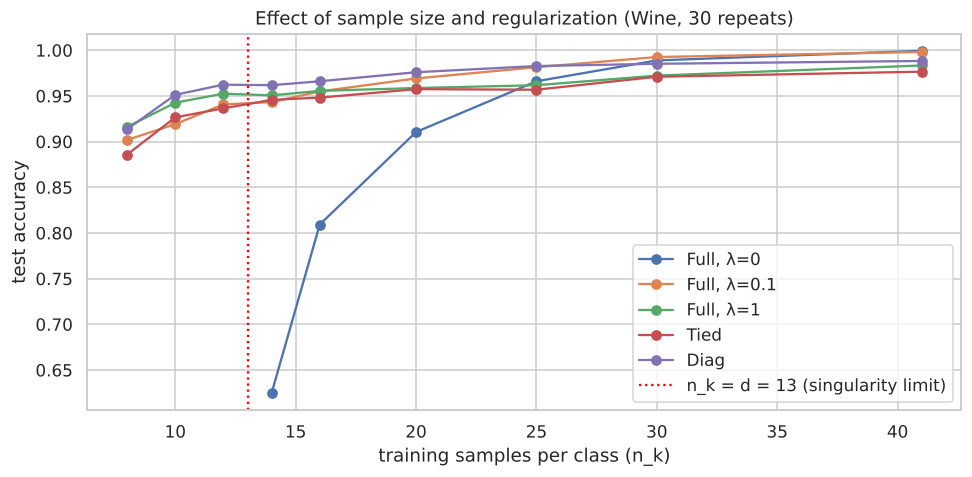

model,Diag,"Full, λ=0","Full, λ=0.1","Full, λ=1",Tied
n_k,,,,,
8,0.914,NaN,0.902,0.916,0.886
10,0.951,NaN,0.919,0.943,0.927
12,0.962,NaN,0.941,0.952,0.936
14,0.962,0.625,0.943,0.951,0.946
16,0.966,0.809,0.955,0.956,0.948
20,0.976,0.910,0.969,0.959,0.957
25,0.983,0.966,0.981,0.962,0.957
30,0.985,0.989,0.993,0.972,0.971
41,0.988,0.999,0.998,0.983,0.977


In [17]:
sizes = [8, 10, 12, 14, 16, 20, 25, 30, 41]   # samples per class
variants = {"Full, λ=0":   lambda: MLEGaussianClassifier("full", 0.0),
            "Full, λ=0.1": lambda: MLEGaussianClassifier("full", 0.1),
            "Full, λ=1":   lambda: MLEGaussianClassifier("full", 1.0),
            "Tied":        lambda: MLEGaussianClassifier("tied"),
            "Diag":        lambda: MLEGaussianClassifier("diag")}
lc_rows = []
for nk in sizes:
    for t in range(30):
        r = np.random.default_rng(t)
        idx = np.concatenate([r.choice(np.where(yw_tr == c)[0], min(nk, np.sum(yw_tr == c)), replace=False)
                              for c in range(3)])
        sc = StandardScaler().fit(Xw_tr[idx])
        for vname, fn in variants.items():
            try:
                acc = fn().fit(sc.transform(Xw_tr[idx]), yw_tr[idx]).score(sc.transform(Xw_te), yw_te)
            except np.linalg.LinAlgError:
                acc = np.nan          # singular covariance → model cannot be built
            lc_rows.append({"n_k": nk, "model": vname, "acc": acc})
lc = pd.DataFrame(lc_rows)
lc_sum = lc.groupby(["model", "n_k"]).acc.agg(mean="mean", fail_rate=lambda s: s.isna().mean()).reset_index()

plt.figure(figsize=(9, 4.5))
for vname in variants:
    s = lc_sum[lc_sum.model == vname]
    plt.plot(s.n_k, s["mean"], "o-", label=vname)
plt.axvline(13, color="red", ls=":", label="n_k = d = 13 (singularity limit)")
plt.xlabel("training samples per class (n_k)"); plt.ylabel("test accuracy")
plt.title("Effect of sample size and regularization (Wine, 30 repeats)"); plt.legend(); plt.tight_layout(); plt.show()

lc_sum.pivot(index="n_k", columns="model", values="mean").round(3)

In [18]:
# how often the un-regularized full model fails outright
lc_sum[lc_sum.model == "Full, λ=0"][["n_k", "fail_rate"]].set_index("n_k").T

n_k,8,10,12,14,16,20,25,30,41
fail_rate,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


**Observations (Part 7)**
- The un-regularized full model **cannot be built at all** for $n_k\le 13$ (singular $\hat{\boldsymbol\Sigma}_k$), and just above the limit its accuracy is poor because $\hat{\boldsymbol\Sigma}_k^{-1}$ is dominated by noise.
- Adding $\lambda\mathbf{I}$ removes the failure and gives stable accuracy at every sample size.
- With few samples, the **diagonal** model (fewest parameters) is the best. With all ~41 samples per class, the **full** model wins. The best model depends on $n_k$ relative to the number of parameters, which is the bias–variance trade-off in action.

### 7.1 Choosing λ by cross-validation

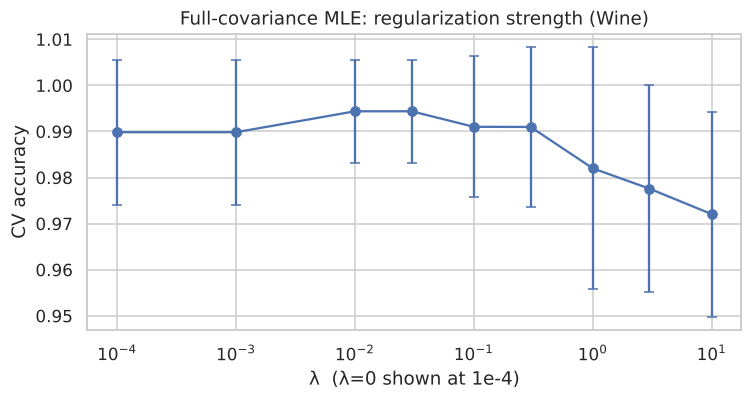

,λ,CV acc,std
0,0.000,0.9898,0.0158
1,0.001,0.9898,0.0158
2,0.010,0.9944,0.0112
3,0.030,0.9944,0.0112
4,0.100,0.9910,0.0153
5,0.300,0.9910,0.0173
6,1.000,0.9820,0.0263
7,3.000,0.9776,0.0225
8,10.000,0.9721,0.0222


In [19]:
lams = [0, 1e-3, 1e-2, 0.03, 0.1, 0.3, 1, 3, 10]
lam_rows = []
for lam in lams:
    mu, sd, _ = repeated_cv(lambda: MLEGaussianClassifier("full", lam), wine.data, wine.target, repeats=5)
    lam_rows.append({"λ": lam, "CV acc": mu, "std": sd})
lam_df = pd.DataFrame(lam_rows)

plt.figure(figsize=(7, 3.8))
x = [1e-4] + lams[1:]
plt.errorbar(x, lam_df["CV acc"], yerr=lam_df["std"], marker="o", capsize=3)
plt.xscale("log"); plt.xlabel("λ  (λ=0 shown at 1e-4)"); plt.ylabel("CV accuracy")
plt.title("Full-covariance MLE: regularization strength (Wine)"); plt.tight_layout(); plt.show()
lam_df.round(4)

### 7.2 Model selection: likelihood vs complexity
The full model always reaches the highest *training* log-likelihood because it has the most parameters. To trade fit against complexity, we use **BIC** $=-2\ell+p\ln n$ (lower is better).

In [20]:
ic_rows = []
for name, m in {"Full": MLEGaussianClassifier("full"), "Tied": MLEGaussianClassifier("tied"),
                "Diag": MLEGaussianClassifier("diag")}.items():
    Xall = StandardScaler().fit_transform(wine.data)
    m.fit(Xall, wine.target)
    ll = m.log_likelihood(Xall, wine.target); p = m.n_parameters(); n = len(Xall)
    ic_rows.append({"model": name, "parameters": p, "train log-likelihood": ll,
                    "AIC": -2 * ll + 2 * p, "BIC": -2 * ll + p * np.log(n)})
pd.DataFrame(ic_rows).round(2)

,model,parameters,train log-likelihood,AIC,BIC
0,Full,314,-1860.22,4348.44,5347.52
1,Tied,132,-2250.05,4764.09,5184.09
2,Diag,80,-2385.02,4930.05,5184.59


**Observation:** the full model has by far the best likelihood and the best AIC, but BIC penalizes its 314 parameters heavily and prefers the tied/diagonal models (nearly equal). The two criteria disagree, and cross-validation (Part 5.4) sides with the full model on Wine once it is lightly regularized.

## Part 8: Evaluation & Conclusions

### Summary of results

In [21]:
summary = cv_df.pivot(index="model", columns="dataset", values="CV accuracy").round(4)
summary["Wine ± std"] = cv_df[cv_df.dataset == "Wine"].set_index("model")["± std"].round(4)
summary["Iris ± std"] = cv_df[cv_df.dataset == "Iris"].set_index("model")["± std"].round(4)
summary[["Wine", "Wine ± std", "Iris", "Iris ± std"]]

dataset,Wine,Wine ± std,Iris,Iris ± std
model,,,,
MLE-Diag (NB),0.9747,0.0226,0.9560,0.0374
MLE-Full (QDA),0.9893,0.0167,0.9700,0.0277
MLE-Full + λ=0.1,0.9916,0.0140,0.9607,0.0357
MLE-Tied (LDA),0.9893,0.0157,0.9787,0.0229


### Evaluation of parameter estimation
1. **Correctness:** the closed-form MLE coincides with the numerical maximum of the log-likelihood (Part 2.1), and the class-conditional densities match SciPy to machine precision (Part 3.1).
2. **Consistency:** errors in $\hat{\boldsymbol\mu}$ and $\hat{\boldsymbol\Sigma}$ decay at roughly $1/\sqrt{n}$ (Part 2.2).
3. **Bias:** $\hat{\boldsymbol\mu}$ is unbiased, while $\hat{\boldsymbol\Sigma}$ underestimates spread by $(n-1)/n$, as theory predicts (Part 2.3). In practice this matters only for very small classes.
4. **Dimensionality:** the number of covariance parameters grows as $O(d^2)$. With $d=13$ and around 40 samples per class, the full covariance is estimable but noisy, and it becomes singular for $n_k\le d$ (Part 7).

### Evaluation of classification performance
1. All MLE-Gaussian variants reach 95–99% cross-validated accuracy on Wine and Iris, so a Gaussian class-conditional model is a good fit for these datasets.
2. On **Wine** ($d=13$, ~59 samples/class), the **regularized full** model is best (≈99.2% CV accuracy). The un-regularized full and tied models are close behind.
3. On **Iris** ($d=4$), the **tied (LDA)** model is best (≈97.9%). The Iris classes have similar shapes, so a shared covariance loses little and halves the estimation variance.
4. The **diagonal** model is the weakest when there is enough data (it ignores feature correlations), but the strongest when data is very scarce (Part 7).
5. The single 70/30 split gave 100% test accuracy for most models, which is misleading on its own. Repeated cross-validation gives the honest picture.
6. **Calibration:** the un-regularized full model's one error was made with 96% confidence (over-confident). The regularized full and tied models made their errors with ≈67–69% confidence, so their posteriors are more trustworthy (Part 5.3).
7. The from-scratch implementation reproduces scikit-learn's QDA/LDA/GNB predictions exactly (Part 6).

### Limitations
- MLE assumes the Gaussian form is **correct**. Multimodal or heavily skewed classes would need mixtures (GMM, fitted with EM) or non-parametric methods (Parzen windows, k-NN).
- MLE gives point estimates only, with no uncertainty over parameters. Bayesian estimation with a prior (e.g. Normal–Inverse-Wishart) naturally regularizes and handles small samples better. Ridge regularization is effectively a crude version of this.
- Both datasets are small and fairly clean, so results on large, noisy, high-dimensional data would need dimensionality reduction (PCA/LDA projection) before full-covariance MLE is feasible.

### Conclusion
We implemented a multi-class pattern recognition system based on Maximum Likelihood Estimation of Gaussian class-conditional densities combined with the Bayes decision rule. Experiments confirmed the theoretical properties of MLE (consistency, the bias of the variance estimator, and singularity when $n_k\le d$). The classifier reaches high accuracy on two standard multi-class benchmarks, and the comparison of covariance assumptions shows that the right model complexity depends on how many samples are available per class, not only on how flexible the model is.